In [1]:
import eu9_osm
import geopandas as gpd
import momepy
import matplotlib.pyplot as plt
import numpy as np
from shapely.affinity import translate

In [2]:
# OSM data 
center_point = 38.4433, -7.3807
buildings = eu9_osm.features_from_point(center_point, tags={"building": True}, dist=350)

In [3]:
# Projection
buildings = buildings.to_crs("EPSG:3763")
# Relevant geometries
buildings = buildings[buildings.geom_type.isin(["Polygon", "MultiPolygon"])].reset_index(drop=True)

In [4]:
# Buffer
limit = momepy.buffered_limit(buildings, buffer=25)
# Thessalation
cells = momepy.morphological_tessellation(buildings, clip=limit, shrink=0.8, segment=0.8)

In [5]:
# Function to create shadow
def shifted_gdf(gdf, dx=10, dy=-10):
    shifted = gdf.copy()
    shifted["geometry"] = shifted.geometry.apply(lambda geom: translate(geom, xoff=dx, yoff=dy))
    return shifted

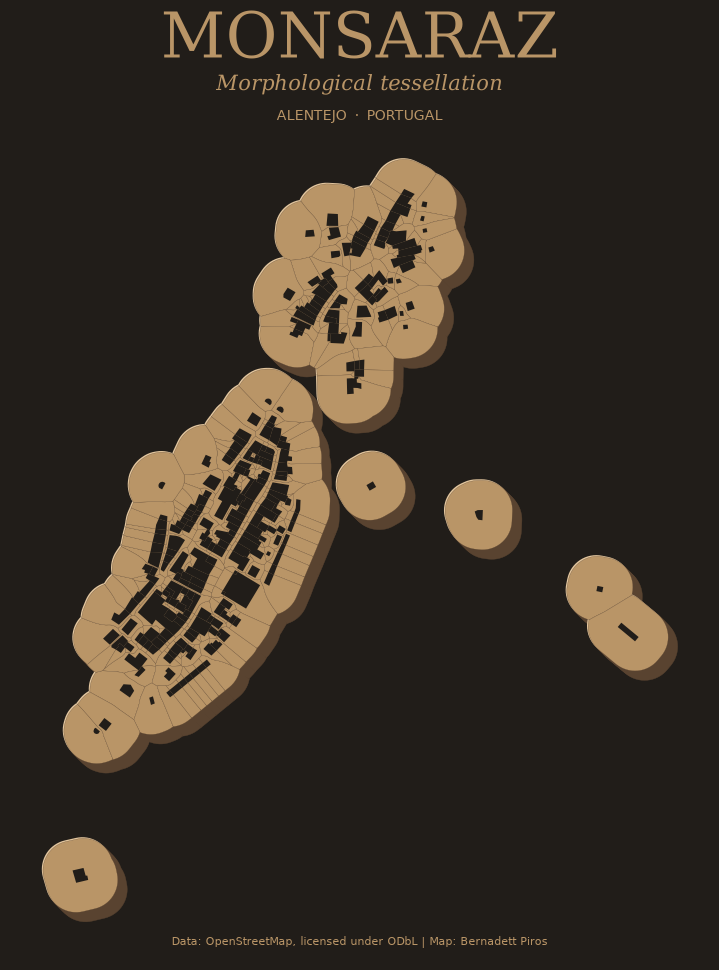

In [6]:
fig, ax = plt.subplots(figsize=(8, 10), facecolor="#211D19")

# Shadow
for shift in range(8, 0, -1):
    shifted_gdf(cells, dx=shift, dy=-shift).plot(ax=ax, color="#594330", ec="#594330", lw=0.3)

# Upper left edges
shifted_gdf(cells, dx=-1, dy=1).plot(ax=ax, color="#E2C59D", ec="none")

# Morphological cells
cells.plot(ax=ax, color="#B99567", ec="#594330", lw=0.18)

# Buildings 
buildings.plot(ax=ax, color="#211D19", ec="none")

ax.set_facecolor("#211D19")
ax.axis("off")

# Title
fig.text(0.5, 0.95,
         "MONSARAZ",
         color="#B99567", size=45, fontfamily="serif", ha="center", va="top")


# Subtitle
fig.text(0.5, 0.87,
         "Morphological tessellation",
         color="#B99567", size=15, fontfamily="serif", fontstyle="italic", ha="center")

# Subtitle II.
fig.text(0.5, 0.84,
         "ALENTEJO  ·  PORTUGAL",
         color="#B99567", ha="center")

# Caption
fig.text(0.5, 0.015,
         "Data: OpenStreetMap, licensed under ODbL | Map: Bernadett Piros", 
         color="#B99567", size=8, ha="center")

plt.subplots_adjust(left=0.03, right=0.97, top=0.84, bottom=0)

plt.show()

#fig.savefig("momepy.png", bbox_inches="tight", pad_inches=0.2)